In [4]:
import numpy as np
import pandas as pd

## Dataset Cleaning

In [5]:
df=pd.read_csv('../group_project/winter_project_2026/development.csv')
eval = pd.read_csv("../group_project/winter_project_2026/evaluation.csv")
df

,Id,source,title,article,page_rank,timestamp,label
0,0,AllAfrica.com,OPEC Boosts Nigeria&#39;s Oil Revenue By .82m Bpd,THE Organisation of Petroleum Exporting Countr...,5,2004-09-16 22:39:53,5
1,1,Xinhua,Yearender: Mideast peace roadmap reaches dead-...,Looking back at the major events that took pla...,5,2004-12-17 19:01:14,0
2,2,Yahoo,Battleground Dispatches for Oct. 5 \\n (CQP...,CQPolitics.com - Here are today's Battleground...,5,2006-10-05 18:42:29,0
3,3,BBC,Air best to resuscitate newborns,Air rather than oxygen should be used to resus...,5,0000-00-00 00:00:00,0
4,4,Yahoo,High tech German train crash kills at least on...,"<p><a href=""http://us.rd.yahoo.com/dailynews/r...",5,2006-09-22 17:28:57,0
...,...,...,...,...,...,...,...
79992,79992,Yahoo,Italy's embattled Prodi faces vote of confiden...,"<p><a href=""http://us.rd.yahoo.com/dailynews/r...",5,2008-01-23 11:39:35,0
79993,79993,All-Baseball.com,"Ding Dong, the Deal is Dead","As yesterday began, there was widespread antic...",5,0000-00-00 00:00:00,4
79994,79994,Yahoo,Two bombs discovered in Sardinia after Berlusc...,AFP - Police discovered two bombs near the Sar...,5,0000-00-00 00:00:00,0
79995,79995,Voice,Red Cross Report Alleges US Detainee Abuse at ...,A report by the International Committee of the...,5,0000-00-00 00:00:00,3


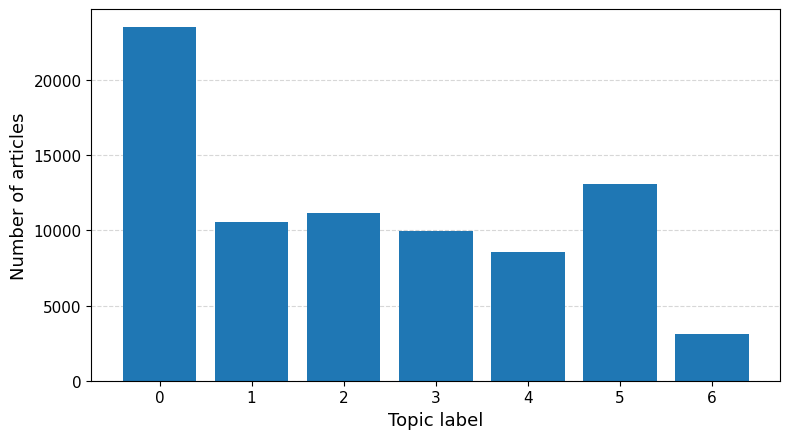

In [6]:
import matplotlib.pyplot as plt

count = df.label.value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
plt.bar(count.index, count.values)

plt.xlabel("Topic label", fontsize=13)
plt.ylabel("Number of articles", fontsize=13)

# ingrandisce i tick di entrambi gli assi
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Grid solo sull'asse y
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.savefig("label_distribution_vector.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
df.info() #c'è un articolo Nan --> non ha senso tenere quella riga

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79997 entries, 0 to 79996
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         79997 non-null  int64 
 1   source     79997 non-null  object
 2   title      79996 non-null  object
 3   article    79996 non-null  object
 4   page_rank  79997 non-null  int64 
 5   timestamp  79997 non-null  object
 6   label      79997 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 4.3+ MB


In [8]:
x_copy=np.vstack((df.iloc[:53004,:],df.iloc[53005:,:]))
df_copy=pd.DataFrame(x_copy,columns=df.columns)
df_copy = df_copy[df_copy['article'].astype(str).str.strip() != '']

In [9]:
# tengo uno solo se ho title e articolo e label uguale
df_copy = df_copy.drop_duplicates(subset=['title', 'article', 'label'], keep='first')
# tolgo tutti e due se hanno titolo e articolo uguale ma label diversa
df_copy = df_copy.drop_duplicates(subset=['title', 'article'], keep=False).copy()

In [10]:
import html
import re
def clean_html(text):
    if not isinstance(text, str):
        return ""
    text=text.lower()
    text = html.unescape(text)

    # rimuovi tutti i tag
    text = re.sub(r'[<>/="]',' ',text)
    # solo lettere
    text = re.sub(r'[^a-z\s]', ' ', text)
    #  togli parole da un carattere
    text = re.sub(r'\b[a-z]\b', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [11]:
df_copy["all_text"] = (df_copy["source"]+ "."+df_copy["title"]+ "." + df_copy["article"])
df_copy.drop(columns = ["article", "title"], inplace=True)
eval["all_text"] = (eval["source"]+"." +eval["title"]+ "." + eval["article"])
eval.drop(columns = ["article", "title"], inplace=True)

In [12]:
df_copy["all_text"] = df_copy["all_text"].apply(clean_html)
#text = df_copy["all_text"]
eval["all_text"] = eval["all_text"].apply(clean_html)

In [13]:
# 1. Pulizia duplicati COERENTI (Stesso testo E stessa label)
# Ne teniamo uno solo per non sbilanciare il training (keep='first')
df_copy = df_copy.drop_duplicates(subset=['all_text', 'label'], keep='first')

# 2. Pulizia CONTRADDIZIONI (Stesso testo ma label DIVERSE)
# Se un testo è rimasto duplicato ora, vuol dire che ha label diverse.
# Questi li eliminiamo TUTTI perché confondono il modello (keep=False)
df_copy = df_copy.drop_duplicates(subset=['all_text'], keep=False)

In [14]:
# 3. Rimuoviamo articoli troppo corti (Rumore)
df_copy = df_copy[df_copy['all_text'].str.len() > 20]

print(f"Righe pulite finali: {len(df_copy)}")

Righe pulite finali: 75357


In [15]:
# 1. Pulizia specifica per i caratteri di "a capo" e spazi strani
# Questo rimuove \n, \r, \t sostituendoli con uno spazio
df_copy['all_text'] = df_copy['all_text'].replace(r'[\n\r\t]+', ' ', regex=True)

# 2. Rimuove eventuali spazi doppi generati dalla sostituzione
df_copy['all_text'] = df_copy['all_text'].replace(r'\s+', ' ', regex=True).str.strip()

In [16]:
df_copy['num_word_log'] = df_copy['all_text'].apply(lambda x: np.log1p(len(str(x).split())))

# 2. Ripeti l'operazione per il set di valutazione (evaluation)
eval['num_word_log'] = eval['all_text'].apply(lambda x: np.log1p(len(str(x).split())))

In [17]:
# --- Correzione Timestamp ---

# 1. Creiamo una feature esplicita che dice al modello: "Occhio, qui mancava la data!"
# Questo preserva l'informazione che "0000" portava (es. forse le News senza data sono tutte General News)
df_copy['date_missing'] = df_copy['timestamp'].str.startswith('0000').astype(int)
eval['date_missing'] = eval['timestamp'].str.startswith('0000').astype(int)

# 2. Convertiamo in datetime coercendo gli errori (0000 diventa NaT - Not a Time)
df_copy['timestamp_dt'] = pd.to_datetime(df_copy['timestamp'], errors='coerce')
eval['timestamp_dt'] = pd.to_datetime(eval['timestamp'], errors='coerce')

# 3. Estraiamo Year, Month, Day lasciando i NaN
# Lasciando NaN, il SimpleImputer nel ColumnTransformer potrà sostituirli con la MEDIA corretta
cols = ['year','day_of_week']

for col in cols:
    if col == 'year':
        df_copy[col] = df_copy['timestamp_dt'].dt.year
        eval[col] = eval['timestamp_dt'].dt.year
    elif col == 'day_of_week':
        df_copy[col] = df_copy['timestamp_dt'].dt.dayofweek
        eval[col] = eval['timestamp_dt'].dt.dayofweek

In [18]:
df_copy

,Id,source,page_rank,timestamp,label,all_text,num_word_log,date_missing,timestamp_dt,year,day_of_week
0,0,AllAfrica.com,5,2004-09-16 22:39:53,5,allafrica com opec boosts nigeria oil revenue ...,3.761200,0,2004-09-16 22:39:53,2004.0,3.0
1,1,Xinhua,5,2004-12-17 19:01:14,0,xinhua yearender mideast peace roadmap reaches...,3.583519,0,2004-12-17 19:01:14,2004.0,4.0
2,2,Yahoo,5,2006-10-05 18:42:29,0,yahoo battleground dispatches for oct cqpoliti...,3.583519,0,2006-10-05 18:42:29,2006.0,3.0
3,3,BBC,5,0000-00-00 00:00:00,0,bbc air best to resuscitate newborns air rathe...,3.218876,1,NaT,NaN,NaN
4,4,Yahoo,5,2006-09-22 17:28:57,0,yahoo high tech german train crash kills at le...,4.762174,0,2006-09-22 17:28:57,2006.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...
79990,79991,RedNova,4,2007-06-25 07:08:21,2,rednova leds move into home lighting market by...,3.637586,0,2007-06-25 07:08:21,2007.0,0.0
79991,79992,Yahoo,5,2008-01-23 11:39:35,0,yahoo italy embattled prodi faces vote of conf...,4.844187,0,2008-01-23 11:39:35,2008.0,2.0
79993,79994,Yahoo,5,0000-00-00 00:00:00,0,yahoo two bombs discovered in sardinia after b...,3.806662,1,NaT,NaN,NaN
79994,79995,Voice,5,0000-00-00 00:00:00,3,voice red cross report alleges us detainee abu...,3.713572,1,NaT,NaN,NaN


In [19]:
X=df_copy.loc[:,["source","all_text","page_rank",'year', 'day_of_week', "date_missing",'num_word_log']]
y=df_copy.loc[:,["label"]]
X_eval = eval.loc[:, ["source", "all_text","page_rank", 'year', 'day_of_week', "date_missing",'num_word_log']]

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_train_ready = y_train["label"].astype(int).values
y_test_ready  = y_test["label"].astype(int).values

## Column Transformer

In [21]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer

num_features = ["page_rank","year", "day_of_week", "date_missing",'num_word_log']
cat_features=["source"]
text=["all_text"]


# Funzione per convertire il DataFrame in una lista 1D per Tfidf
def to_list(x):
    return x.iloc[:, 0].tolist()

preproc = ColumnTransformer(
    [
        # 1. Numeriche: Missing values con la media + Standardizzazione
        ("num", make_pipeline(SimpleImputer(strategy='mean'), StandardScaler()), num_features),



         ("text", make_pipeline(FunctionTransformer(to_list, validate=False), TfidfVectorizer(min_df=2, max_df=0.50, ngram_range=(1,3),sublinear_tf=True, stop_words="english", strip_accents='unicode'),
                               ), text),

        # 3. Categoriche: Missing values con la moda + One-Hot Encoding
        ("cat", make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown="ignore")), cat_features)
    ],
    remainder="drop", # Le colonne non specificate non vengono modificate
    verbose_feature_names_out=True

)

## Gridsearch

1. **Logistic Regression**

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from tqdm import tqdm


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_lr = {
    "clf__C": [ 1, 4, 5, 10, 20],
    "clf__class_weight": ["balanced"],

    "preproc__text__tfidfvectorizer__ngram_range": [(1,2), (1,3)],
    "preproc__text__tfidfvectorizer__min_df": [2, 5],
    "preproc__text__tfidfvectorizer__max_df":  [0.3,0.5],
    "preproc__text__tfidfvectorizer__sublinear_tf": [True],
    # opzionale: se vuoi testarlo
    "preproc__text__tfidfvectorizer__stop_words": ["english"],
}
scores = []

for params in tqdm(ParameterGrid(grid_lr), desc="LogReg grid"):
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train_ready):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_va = y_train_ready[train_idx], y_train_ready[val_idx]

        pipe = Pipeline([
            ("preproc", preproc),
            ("clf", LogisticRegression(
                solver="saga", max_iter=1000, random_state=42
            ))
        ])
        pipe.set_params(**params)

        pipe.fit(X_tr, y_tr)
        pred = pipe.predict(X_va)
        fold_scores.append(f1_score(y_va, pred, average="macro"))

    scores.append({
        "params": params,
        "mean_f1": np.mean(fold_scores),
        "std_f1": np.std(fold_scores)
    })



LogReg grid: 100%|██████████| 40/40 [56:22<00:00, 84.55s/it] 


In [24]:
best_lr_cfg = max(scores, key=lambda x: x["mean_f1"])

print("Best mean F1:", best_lr_cfg["mean_f1"])
print("Best params:", best_lr_cfg["params"])

Best mean F1: 0.7293119720339304
Best params: {'clf__C': 4, 'clf__class_weight': 'balanced', 'preproc__text__tfidfvectorizer__max_df': 0.3, 'preproc__text__tfidfvectorizer__min_df': 2, 'preproc__text__tfidfvectorizer__ngram_range': (1, 3), 'preproc__text__tfidfvectorizer__stop_words': 'english', 'preproc__text__tfidfvectorizer__sublinear_tf': True}


2. **Linear SVC**

In [38]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import ParameterGrid

grid_svm = {
    # ---- classificatore ----
    "clf__C": [0.1,0.5, 1, 5, 10],
    "clf__class_weight": ["balanced"],

    # ---- TF-IDF ----
    "preproc__text__tfidfvectorizer__ngram_range": [(1,2), (1,3)],
    "preproc__text__tfidfvectorizer__min_df": [2, 5],
    "preproc__text__tfidfvectorizer__max_df": [0.3,0.5],
    "preproc__text__tfidfvectorizer__sublinear_tf": [True],
    "preproc__text__tfidfvectorizer__stop_words": ["english"],
}

scores_svm = []

for params in tqdm(ParameterGrid(grid_svm), desc="LinearSVC grid"):
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train_ready):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_va = y_train_ready[train_idx], y_train_ready[val_idx]

        pipe = Pipeline([
            ("preproc", preproc),
            ("clf", LinearSVC(max_iter=10000))
        ])
        pipe.set_params(**params)

        pipe.fit(X_tr, y_tr)
        pred = pipe.predict(X_va)
        fold_scores.append(f1_score(y_va, pred, average="macro"))

    scores_svm.append({
        "params": params,
        "mean_f1": np.mean(fold_scores),
        "std_f1": np.std(fold_scores)
    })

LinearSVC grid: 100%|██████████| 40/40 [41:32<00:00, 62.31s/it] 


In [39]:
scores_svm

[{'params': {'clf__C': 0.1,
   'clf__class_weight': 'balanced',
   'preproc__text__tfidfvectorizer__max_df': 0.3,
   'preproc__text__tfidfvectorizer__min_df': 2,
   'preproc__text__tfidfvectorizer__ngram_range': (1, 2),
   'preproc__text__tfidfvectorizer__stop_words': 'english',
   'preproc__text__tfidfvectorizer__sublinear_tf': True},
  'mean_f1': np.float64(0.7274294647912551),
  'std_f1': np.float64(0.0005995268909819431)},
 {'params': {'clf__C': 0.1,
   'clf__class_weight': 'balanced',
   'preproc__text__tfidfvectorizer__max_df': 0.3,
   'preproc__text__tfidfvectorizer__min_df': 2,
   'preproc__text__tfidfvectorizer__ngram_range': (1, 3),
   'preproc__text__tfidfvectorizer__stop_words': 'english',
   'preproc__text__tfidfvectorizer__sublinear_tf': True},
  'mean_f1': np.float64(0.7288228005149286),
  'std_f1': np.float64(0.0009773883258060816)},
 {'params': {'clf__C': 0.1,
   'clf__class_weight': 'balanced',
   'preproc__text__tfidfvectorizer__max_df': 0.3,
   'preproc__text__tfidf

In [40]:
# print("SVM best CV:", gs_svm.best_score_, gs_svm.best_params_)
best_svm_cfg = max(scores_svm, key=lambda x: x["mean_f1"])

print("Best mean F1:", best_svm_cfg["mean_f1"])
print("Best params:", best_svm_cfg["params"])

Best mean F1: 0.730389839572079
Best params: {'clf__C': 0.5, 'clf__class_weight': 'balanced', 'preproc__text__tfidfvectorizer__max_df': 0.3, 'preproc__text__tfidfvectorizer__min_df': 2, 'preproc__text__tfidfvectorizer__ngram_range': (1, 3), 'preproc__text__tfidfvectorizer__stop_words': 'english', 'preproc__text__tfidfvectorizer__sublinear_tf': True}


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from tqdm import tqdm

# --- 1) Logistic Regression: refit su tutto train, poi test ---
lr_pipe = Pipeline([
    ("preproc", preproc),
    ("clf", LogisticRegression(solver="saga", max_iter=1000, random_state=42))
])

best_lr_params = {
    "clf__C": 4,
    "clf__class_weight": "balanced",
    "preproc__text__tfidfvectorizer__max_df": 0.3,
    "preproc__text__tfidfvectorizer__min_df": 2,
    "preproc__text__tfidfvectorizer__ngram_range": (1, 3),
    "preproc__text__tfidfvectorizer__stop_words": "english",
    "preproc__text__tfidfvectorizer__sublinear_tf": True,
}

lr_pipe.set_params(**best_lr_params)
lr_pipe.fit(X_train, y_train_ready)

lr_pred = lr_pipe.predict(X_test)
lr_f1 = f1_score(y_test_ready, lr_pred, average="macro")
print(f"LogReg TEST macro-F1: {lr_f1:.4f}")

# --- 2) LinearSVC: refit su tutto train, poi test ---
svm_pipe = Pipeline([
    ("preproc", preproc),
    ("clf", LinearSVC(max_iter=10000))
])

best_svm_params={
 'clf__C': 0.5,
 'clf__class_weight': 'balanced',
 'preproc__text__tfidfvectorizer__max_df': 0.3,
 'preproc__text__tfidfvectorizer__min_df': 2,
 'preproc__text__tfidfvectorizer__ngram_range': (1, 3),
 'preproc__text__tfidfvectorizer__stop_words': 'english',
 'preproc__text__tfidfvectorizer__sublinear_tf': True
}

svm_pipe.set_params(**best_svm_params)
svm_pipe.fit(X_train, y_train_ready)

svm_pred = svm_pipe.predict(X_test)
svm_f1 = f1_score(y_test_ready, svm_pred, average="macro")
print(f"LinearSVC TEST macro-F1: {svm_f1:.4f}")

LogReg TEST macro-F1: 0.7403
LinearSVC TEST macro-F1: 0.7431


Confusion Matrix Logistic Regression

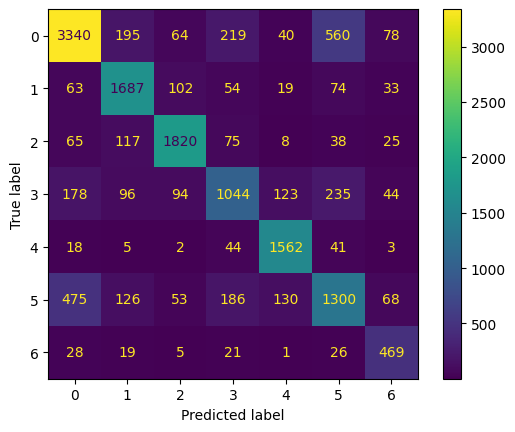

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_ready, lr_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

Confusion Matrix SVM

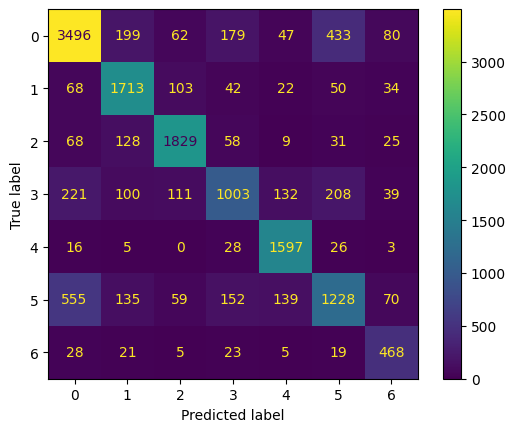

In [35]:
cm = confusion_matrix(y_test_ready, svm_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

**Plots**

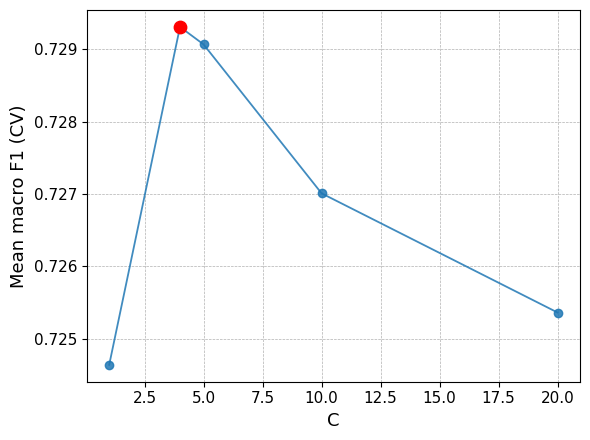

In [44]:
filtered = [
    d for d in scores
    if d["params"].get("preproc__text__tfidfvectorizer__ngram_range") == (1, 3)
    and d["params"].get("preproc__text__tfidfvectorizer__min_df") == 2
    and d["params"].get("preproc__text__tfidfvectorizer__max_df") == 0.3
]

pairs = [(d["params"]["clf__C"], float(d["mean_f1"])) for d in filtered]
pairs.sort(key=lambda x: x[0])
Cs, mean_f1 = zip(*pairs)

best_idx = int(np.argmax(mean_f1))
best_C = Cs[best_idx]
best_f1 = mean_f1[best_idx]

plt.figure(figsize=(6, 4.5))

plt.plot(
    Cs,
    mean_f1,
    color="tab:blue",
    linewidth=1.3,
    marker="o",
    markersize=6,
    alpha=0.85
)

plt.scatter(
    [best_C],
    [best_f1],
    color="red",
    s=80,
    zorder=3
)

plt.xlabel("C", fontsize=13)
plt.ylabel("Mean macro F1 (CV)", fontsize=13)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.savefig("params_lr.pdf", dpi=300, bbox_inches="tight")
plt.show()

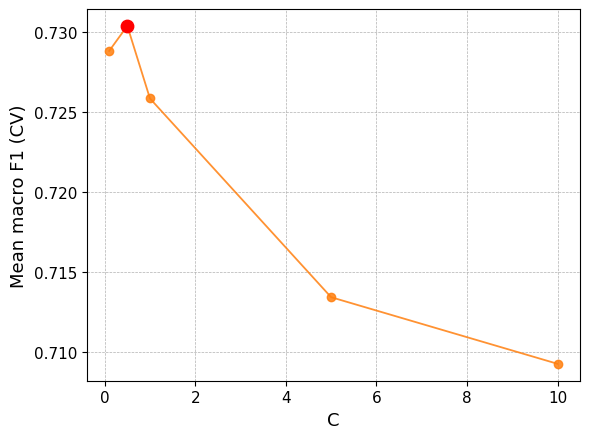

In [43]:
filtered = [
    d for d in scores_svm
    if d["params"].get("preproc__text__tfidfvectorizer__ngram_range") == (1, 3)
    and d["params"].get("preproc__text__tfidfvectorizer__min_df") == 2
    and d["params"].get("preproc__text__tfidfvectorizer__max_df") == 0.3
]

pairs = [(d["params"]["clf__C"], float(d["mean_f1"])) for d in filtered]
pairs.sort(key=lambda x: x[0])
Cs, mean_f1 = zip(*pairs)

best_idx = int(np.argmax(mean_f1))
best_C = Cs[best_idx]
best_f1 = mean_f1[best_idx]

plt.figure(figsize=(6, 4.5))

plt.plot(
    Cs,
    mean_f1,
    color="tab:orange",
    linewidth=1.3,
    marker="o",
    markersize=6,
    alpha=0.85
)

plt.scatter(
    [best_C],
    [best_f1],
    color="red",
    s=80,
    zorder=3
)

plt.xlabel("C", fontsize=13)
plt.ylabel("Mean macro F1 (CV)", fontsize=13)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.savefig("params_svm.pdf", dpi=300, bbox_inches="tight")
plt.show()